In [94]:
import pandas as pd
donnees = pd.read_csv("etudiants_classification_500 (2).csv")
donnees

,etudiant,heures_etude,note_partiel,resultat
0,E001,1.0,3.0,Échec
1,E002,2.0,5.0,Échec
2,E003,3.0,2.0,Échec
3,E004,4.0,6.0,Réussite
4,E005,6.0,7.0,Réussite
...,...,...,...,...
495,E496,1.0,1.5,Échec
496,E497,7.2,9.4,Réussite
497,E498,7.8,3.3,Échec
498,E499,4.2,5.4,Échec


In [95]:
donnees["resultat"] = donnees["resultat"].map({"Échec": 0, "Réussite": 1})

In [96]:
donnees["resultat"].unique()

array([0, 1])

In [97]:
X = donnees.drop(["etudiant", "resultat"], axis=1)
y = donnees ["resultat"]

In [98]:
from sklearn.model_selection import train_test_split


In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [100]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [101]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [102]:
modeles = {
    "SVM": make_pipeline(StandardScaler(), SVC(kernel = "rbf", C = 1)),
    "DT": DecisionTreeClassifier(max_depth = 4, random_state = 42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors = 5))
}

In [103]:
import matplotlib.pyplot as plt
resultat = []
meilleur_score = 0
meilleur_modele = None
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

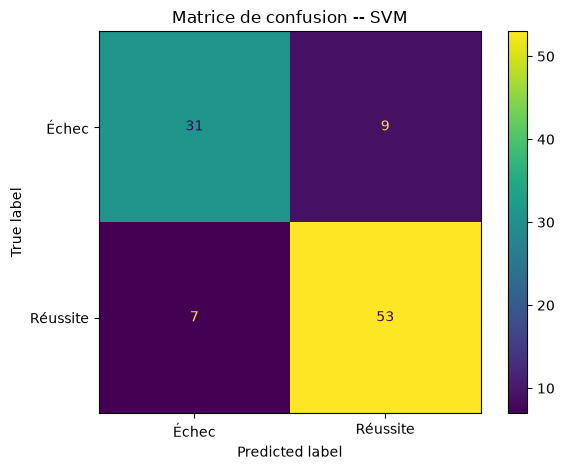

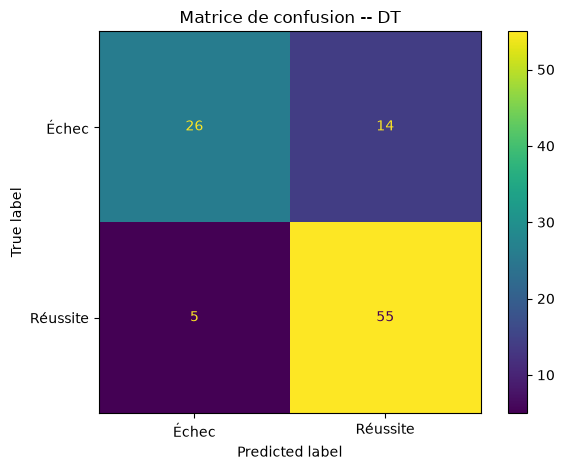

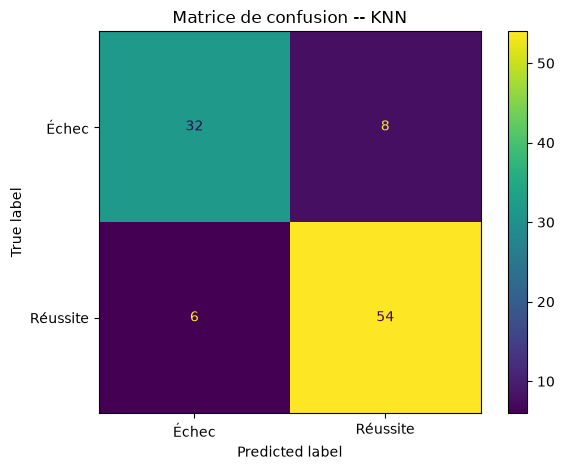

In [104]:
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred)
    resultat.append([nom, accuracy, precision, recall, f1])
    matrice = confusion_matrix(y_test, y_pred, labels=[0,1])
    affichage = ConfusionMatrixDisplay(confusion_matrix = matrice, display_labels = ["Échec", "Réussite"])
    affichage.plot(values_format = "d")
    plt.title(f"Matrice de confusion -- {nom}")
    plt.tight_layout()

    if f1 > meilleur_score:
        meilleur_score= f1
        meilleur_modele = modele

In [105]:
import joblib

In [107]:
joblib.dump(meilleur_modele, "monModeleML.joblib")
["monModeleML.joblib"]

['monModeleML.joblib']